# Iris: klasyfikacja

<table>
<tr>
<td><img src="https://upload.wikimedia.org/wikipedia/commons/thumb/5/56/Kosaciec_szczecinkowaty_Iris_setosa.jpg/330px-Kosaciec_szczecinkowaty_Iris_setosa.jpg" height="200" alt="Iris setosa"></td>
<td><img src="https://upload.wikimedia.org/wikipedia/commons/thumb/4/41/Iris_versicolor_3.jpg/330px-Iris_versicolor_3.jpg" height="200" alt="Iris versicolor"></td>
<td><img src="https://upload.wikimedia.org/wikipedia/commons/thumb/9/9f/Iris_virginica.jpg/330px-Iris_virginica.jpg" height="200" alt="Iris virginica"></td>
</tr>
<tr>
<td align="center"><i>Iris setosa</i></td>
<td align="center"><i>Iris versicolor</i></td>
<td align="center"><i>Iris virginica</i></td>
</tr>
</table>

W **klasyfikacji** przewidujemy, do której z wcześniej określonych klas należy obiekt. To uczenie nadzorowane:
zbiór treningowy zawiera zarówno cechy obiektów, jak i poprawne etykiety klas. Tutaj cechami są wymiary kwiatu,
a etykietą gatunek irysa.

## 1. Wczytanie danych

Zbiór Iris (R.A. Fisher, 1936) zawiera pomiary 150 kwiatów z trzech gatunków irysa, po 50 z każdego.

| Kolumna | Opis |
|---|---|
| `sepal.length` | długość działki kielicha [cm] |
| `sepal.width` | szerokość działki kielicha [cm] |
| `petal.length` | długość płatka korony [cm] |
| `petal.width` | szerokość płatka korony [cm] |
| `Species` | gatunek (etykieta) |

In [15]:
from pathlib import Path
import pandas as pd

URL = "https://raw.githubusercontent.com/DownDev/elementy-sztucznej-inteligencji/main/02-iris/iris.csv"
df = pd.read_csv("iris.csv" if Path("iris.csv").exists() else URL)
df

,sepal.length,sepal.width,petal.length,petal.width,Species
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica


## 2. Kontrola danych

### Typy danych

In [16]:
df.dtypes

sepal.length    float64
sepal.width     float64
petal.length    float64
petal.width     float64
Species          object
dtype: object

Cechy mają typ `float64`, a gatunek to tekst.

### Jednostki

Plik nie podaje jednostek, więc sprawdzamy zakresy wartości.

In [17]:
df.describe().round(2)

,sepal.length,sepal.width,petal.length,petal.width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


Zakresy pasują do centymetrów: działki kielicha mają od 4,3 do 7,9 cm długości, a płatki od 0,1 do 2,5 cm szerokości.
Nie ma wartości ujemnych ani zerowych. Wszystkie cechy są w tej samej jednostce, więc nie trzeba ich przeliczać.

### Braki i duplikaty

In [18]:
print("Braki w kolumnach:", df.isna().sum().to_dict())
df[df.duplicated(keep=False)]

Braki w kolumnach: {'sepal.length': 0, 'sepal.width': 0, 'petal.length': 0, 'petal.width': 0, 'Species': 0}


,sepal.length,sepal.width,petal.length,petal.width,Species
101,5.8,2.7,5.1,1.9,Virginica
142,5.8,2.7,5.1,1.9,Virginica


Braków nie ma, więc uzupełnianie wartości nie jest potrzebne. Jeden wiersz występuje dwa razy, więc usuwamy kopię,
żeby ten sam kwiat nie trafił do obu zbiorów.

In [19]:
df = df.drop_duplicates().reset_index(drop=True)
df["Species"].value_counts()

Species
Setosa        50
Versicolor    50
Virginica     49
Name: count, dtype: int64

Klasy są prawie równoliczne (50, 50 i 49 kwiatów).

### Wykresy rozrzutu

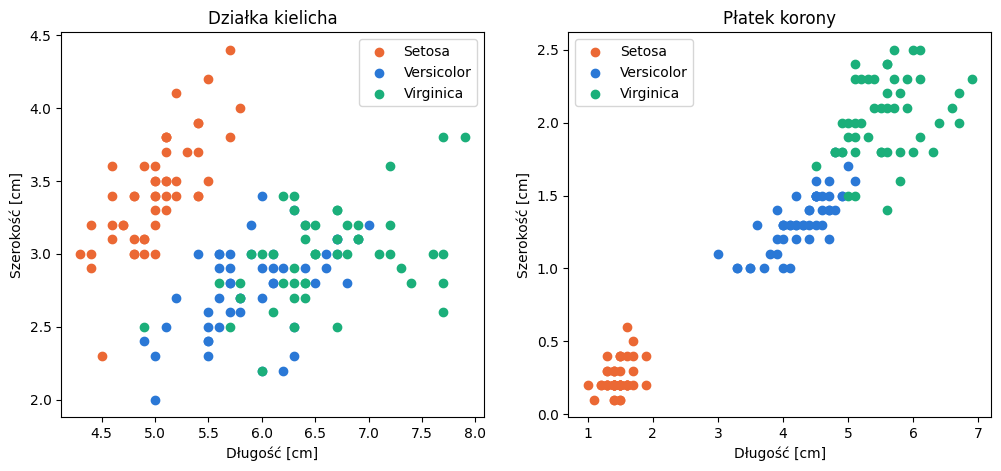

In [20]:
import matplotlib.pyplot as plt

COLORS = {"Setosa": "#eb6834", "Versicolor": "#2a78d6", "Virginica": "#1baf7a"}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, part, name in zip(axes, ["sepal", "petal"], ["Działka kielicha", "Płatek korony"]):
    for species, group in df.groupby("Species"):
        ax.scatter(group[f"{part}.length"], group[f"{part}.width"], label=species, color=COLORS[species])
    ax.set_xlabel("Długość [cm]")
    ax.set_ylabel("Szerokość [cm]")
    ax.set_title(name)
    ax.legend()
plt.show()

Po wymiarach płatków *Setosa* jest wyraźnie oddzielona od pozostałych gatunków. *Versicolor* i *Virginica* częściowo
na siebie nachodzą, więc tam należy się spodziewać błędów klasyfikacji.

## 3. Cechy, etykiety i podział danych

Cechy `X` to cztery kolumny z wymiarami, a etykiety `y` to kolumna `Species`.

30% danych (45 kwiatów) odkładamy jako **zbiór testowy** i nie korzystamy z niego aż do końcowej oceny. Parametr
`stratify=y` zachowuje proporcje klas w obu zbiorach, a `random_state` sprawia, że podział jest powtarzalny.

In [21]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="Species")
y = df["Species"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

pd.DataFrame({"trening": y_train.value_counts(), "test": y_test.value_counts()})

,trening,test
Species,,
Setosa,35,15
Versicolor,35,15
Virginica,34,15


## 4. Skalowanie cech

k-NN ocenia podobieństwo kwiatów odległością euklidesową między wektorami cech $a$ i $b$:

$$
d(a, b) = \sqrt{\sum_{j} (a_j - b_j)^2}
$$

Cecha o dużym rozrzucie wartości zdominowałaby tę sumę. Dlatego standaryzujemy każdą cechę:

$$
z = \frac{x - \mu}{\sigma}
$$

gdzie $\mu$ to średnia, a $\sigma$ odchylenie standardowe cechy. Obie wartości wyznaczamy **tylko na zbiorze
treningowym** i tymi samymi liczbami przekształcamy oba zbiory. Gdyby skaler widział zbiór testowy, informacja z testu
przeciekłaby do modelu.

In [22]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)  # μ i σ tylko ze zbioru treningowego
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame({
    "μ (trening)": scaler.mean_,
    "σ (trening)": scaler.scale_,
    "średnia po skalowaniu: trening": X_train_scaled.mean(axis=0),
    "średnia po skalowaniu: test": X_test_scaled.mean(axis=0),
}, index=X.columns).round(2)

,μ (trening),σ (trening),średnia po skalowaniu: trening,średnia po skalowaniu: test
sepal.length,5.90,0.86,0.0,-0.22
sepal.width,3.07,0.45,-0.0,-0.06
petal.length,3.78,1.78,-0.0,-0.06
petal.width,1.20,0.77,0.0,-0.03


Po skalowaniu cechy zbioru treningowego mają średnią dokładnie 0, a testowego tylko w przybliżeniu.

Ta sama zasada obowiązuje w walidacji krzyżowej: część walidacyjna pełni rolę małego zbioru testowego, więc skaler
trzeba dopasować na pozostałej części. Robi to **potok** (`Pipeline`), np.
`make_pipeline(StandardScaler(), KNeighborsClassifier())`: metoda `fit()` uczy skaler i model na podanych danych,
a `predict()` używa już wyznaczonych parametrów.

## 5. k-najbliższych sąsiadów

**k-NN** (*k-nearest neighbors*) nowemu kwiatowi przypisuje gatunek najczęściej występujący wśród jego `k`
najbliższych sąsiadów ze zbioru treningowego. Małe `k` sprawia, że model podąża za pojedynczymi, być może nietypowymi
punktami. Duże `k` rozmywa granice między klasami.

### Dobór `k` walidacją krzyżową

Hiperparametr `k` dobieramy na zbiorze treningowym, bez użycia zbioru testowego. W **walidacji krzyżowej** dzielimy
zbiór treningowy na 5 części: każda raz służy do oceny modelu nauczonego na pozostałych czterech.
`RepeatedStratifiedKFold` powtarza to 10 razy przy różnym przetasowaniu danych, bo w jednej części jest tylko około 21
kwiatów i pojedynczy błąd zmienia wynik o prawie 5 punktów procentowych.

`GridSearchCV` sprawdza każde `k` od 1 do 30 na tych samych podziałach. Dla porównania liczymy też k-NN bez skalowania.

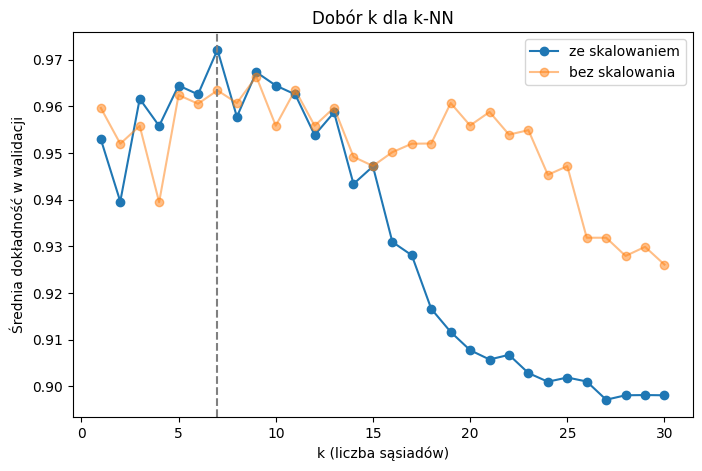

Najlepsze k = 7, dokładność w walidacji: 0.972
Bez skalowania: k = 9, dokładność: 0.966


In [23]:
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
K = range(1, 31)

knn_search = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                          {"kneighborsclassifier__n_neighbors": K}, cv=cv)
knn_search.fit(X_train, y_train)
best_k = knn_search.best_params_["kneighborsclassifier__n_neighbors"]

raw_search = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": K}, cv=cv)
raw_search.fit(X_train, y_train)

plt.figure(figsize=(8, 5))
plt.plot(K, knn_search.cv_results_["mean_test_score"], marker="o", label="ze skalowaniem")
plt.plot(K, raw_search.cv_results_["mean_test_score"], marker="o", alpha=0.5, label="bez skalowania")
plt.axvline(best_k, color="gray", linestyle="--")
plt.xlabel("k (liczba sąsiadów)")
plt.ylabel("Średnia dokładność w walidacji")
plt.title("Dobór k dla k-NN")
plt.legend()
plt.show()

print(f"Najlepsze k = {best_k}, dokładność w walidacji: {knn_search.best_score_:.3f}")
print(f"Bez skalowania: k = {raw_search.best_params_['n_neighbors']}, dokładność: {raw_search.best_score_:.3f}")

Najlepsze jest `k = 7` (dokładność 0,972). Przy `k = 1` i `k = 2` wynik jest gorszy, bo model podąża za
pojedynczymi punktami. Od około `k = 14` dokładność spada, bo sąsiedztwo zaczyna obejmować kwiaty innych gatunków.

Bez skalowania najlepszy wynik jest niewiele gorszy (0,966 dla `k = 9`), a dla dużych `k` nawet lepszy. W zbiorze
Iris wszystkie cechy są w centymetrach, a bez skalowania odległość zależy głównie od długości płatka, która ma
największy rozrzut ($\sigma \approx 1{,}8$ cm) i akurat najlepiej rozróżnia gatunki. Po skalowaniu słabsze działki
kielicha liczą się tak samo jak płatki. Skalowanie byłoby znacznie ważniejsze np. dla pingwinów z poprzedniego
zadania, gdzie masa ciała w gramach (tysiące) sąsiaduje z wymiarami dzioba w milimetrach (dziesiątki).

## 6. Porównanie algorytmów

Oprócz k-NN sprawdzamy cztery inne popularne klasyfikatory z domyślnymi hiperparametrami:

- **regresja logistyczna** wyznacza liniowe granice między klasami;
- **SVM** (maszyna wektorów nośnych) z jądrem RBF może tworzyć granice zakrzywione;
- **drzewo decyzyjne** zadaje serię pytań o progi pojedynczych cech, np. „czy płatek jest krótszy niż 2,5 cm?”;
- **naiwny klasyfikator Bayesa** zakłada, że w każdej klasie każda cecha ma rozkład normalny.

Drzewo i naiwny Bayes porównują każdą cechę osobno, a nie liczą odległości, więc nie wymagają skalowania. Wszystkie
modele oceniamy na **tych samych podziałach walidacji krzyżowej** (`cv`) zbioru treningowego.

### Miary jakości

Dla wybranej klasy liczymy przykłady prawdziwie pozytywne ($TP$, model wskazał klasę i miał rację), fałszywie
pozytywne ($FP$, wskazał klasę, a to inny gatunek) i fałszywie negatywne ($FN$, nie wskazał klasy, choć powinien).

- **Dokładność** (*accuracy*): odsetek wszystkich poprawnych odpowiedzi.
- **Precyzja** (*precision*): ile spośród kwiatów wskazanych jako dany gatunek naprawdę nim jest.
  $\quad P = \frac{TP}{TP + FP}$
- **Czułość** (*recall*): ile kwiatów danego gatunku model odnalazł.
  $\quad R = \frac{TP}{TP + FN}$
- **F1**: średnia harmoniczna precyzji i czułości.
  $\quad F_1 = \frac{2 P R}{P + R}$

Przy trzech klasach precyzję, czułość i F1 liczymy dla każdej klasy osobno i uśredniamy. **Średnia makro**
(`_macro`) traktuje wszystkie klasy jednakowo. Więcej o miarach:
[Precision, recall, F1: miary oceny klasyfikatora](https://ksopyla.com/data-science/precision-recall-f1-miary-oceny-klasyfikatora/).

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

models = {
    f"k-NN (k={best_k})": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k)),
    "Regresja logistyczna": make_pipeline(StandardScaler(), LogisticRegression()),
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "Drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "Naiwny Bayes": GaussianNB(),
}
METRICS = {"accuracy": "dokładność", "precision_macro": "precyzja", "recall_macro": "czułość", "f1_macro": "F1"}

rows = {}
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=list(METRICS))
    rows[name] = {label: scores[f"test_{metric}"].mean() for metric, label in METRICS.items()}
    rows[name]["F1: odch. std."] = scores["test_f1_macro"].std()

results = pd.DataFrame(rows).T.sort_values("F1", ascending=False)
results.round(3)

,dokładność,precyzja,czułość,F1,F1: odch. std.
Naiwny Bayes,0.979,0.981,0.979,0.979,0.029
Regresja logistyczna,0.977,0.979,0.977,0.977,0.028
k-NN (k=7),0.972,0.976,0.972,0.972,0.031
SVM,0.966,0.972,0.967,0.965,0.045
Drzewo decyzyjne,0.937,0.948,0.937,0.935,0.048


### Macierze pomyłek

Macierz pomyłek pokazuje, które klasy są ze sobą mylone. Wiersze to prawdziwe gatunki, kolumny to przewidywane,
a poprawne odpowiedzi leżą na przekątnej. `cross_val_predict` przeprowadza jedno przejście 5-krotnej walidacji,
więc każdy kwiat treningowy dostaje jedną prognozę.

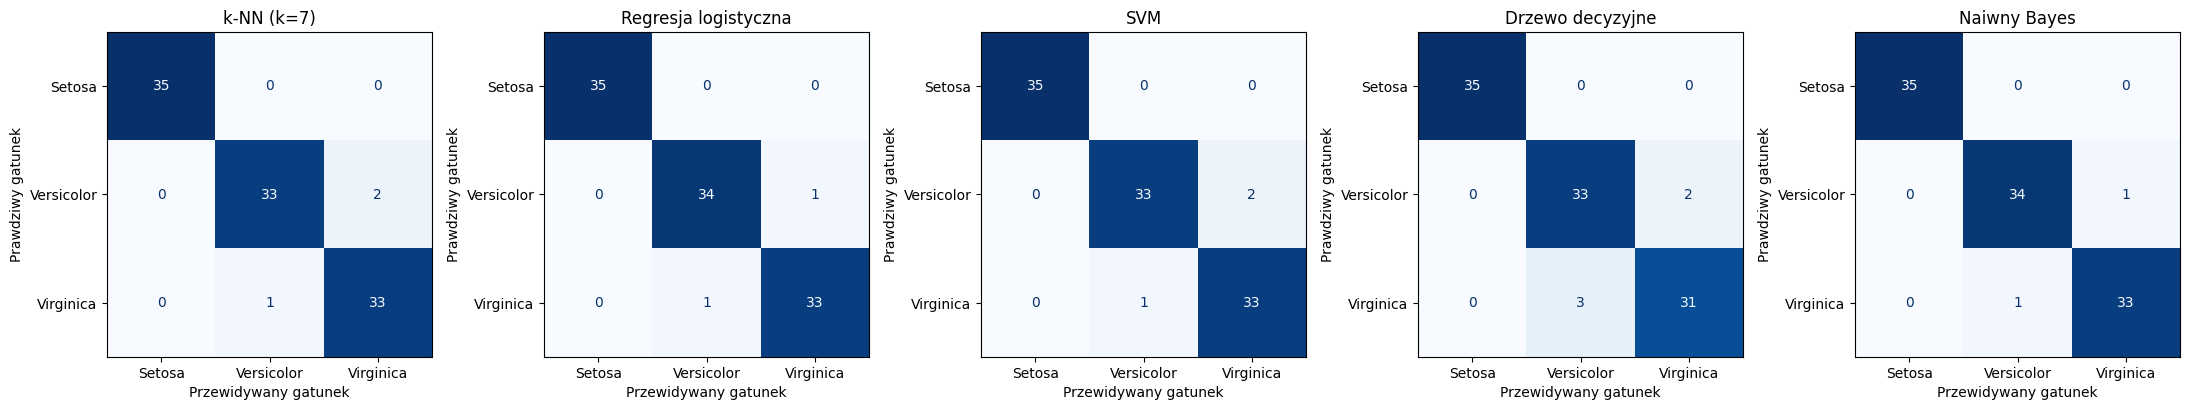

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv_once = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fig, axes = plt.subplots(1, len(models), figsize=(22, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    y_pred = cross_val_predict(model, X_train, y_train, cv=cv_once)
    ConfusionMatrixDisplay.from_predictions(y_train, y_pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.set_xlabel("Przewidywany gatunek")
    ax.set_ylabel("Prawdziwy gatunek")
plt.tight_layout()
plt.show()

Wszystkie modele bezbłędnie rozpoznają *Setosę*, a każdy błąd to pomyłka między *Versicolor* i *Virginicą*.

Naiwny Bayes, regresja logistyczna, k-NN i SVM różnią się średnim F1 o niecałe 1,5 punktu procentowego. To mniej niż
odchylenie standardowe między podziałami (3–5 punktów), więc na tych danych są praktycznie równie dobre. Wyraźnie
słabsze jest tylko drzewo decyzyjne. Wynik k-NN jest przy tym lekko zawyżony, bo `k` dobieraliśmy na tych samych
podziałach.

Wybieramy model z najwyższym średnim F1 w walidacji.

In [26]:
best_name = results.index[0]
final_model = models[best_name]
best_name

'Naiwny Bayes'

## 7. Końcowa ocena na zbiorze testowym

Wybrany model uczymy na całym zbiorze treningowym i oceniamy na zbiorze testowym.
W raporcie `precision` to precyzja, `recall` to czułość, a `support` to liczba kwiatów danego gatunku.

Naiwny Bayes: dokładność na zbiorze testowym 0.911

              precision    recall  f1-score   support

      Setosa      1.000     1.000     1.000        15
  Versicolor      0.824     0.933     0.875        15
   Virginica      0.923     0.800     0.857        15

    accuracy                          0.911        45
   macro avg      0.916     0.911     0.911        45
weighted avg      0.916     0.911     0.911        45



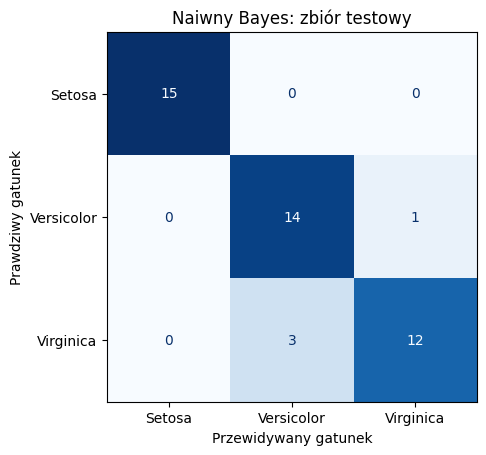

In [27]:
from sklearn.metrics import accuracy_score, classification_report

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

print(f"{best_name}: dokładność na zbiorze testowym {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False)
plt.title(f"{best_name}: zbiór testowy")
plt.xlabel("Przewidywany gatunek")
plt.ylabel("Prawdziwy gatunek")
plt.show()

Błędnie sklasyfikowane kwiaty:

In [28]:
wrong = y_pred != y_test
X_test[wrong].assign(gatunek=y_test[wrong], prognoza=y_pred[wrong])

,sepal.length,sepal.width,petal.length,petal.width,gatunek,prognoza
106,4.9,2.5,4.5,1.7,Virginica,Versicolor
133,6.3,2.8,5.1,1.5,Virginica,Versicolor
77,6.7,3.0,5.0,1.7,Versicolor,Virginica
134,6.1,2.6,5.6,1.4,Virginica,Versicolor


Model pomylił 4 z 45 kwiatów (dokładność i F1 makro 0,911). *Setosę* rozpoznał bezbłędnie. Trzy *Virginiki*
uznał za *Versicolor*, stąd czułość 0,80 dla *Virginiki*, i jedną *Versicolor* za *Virginicę*. Wszystkie te kwiaty
mają płatki o pośrednich wymiarach (4,5–5,6 cm długości, 1,4–1,7 cm szerokości), czyli leżą w obszarze, w którym
oba gatunki na siebie nachodzą.

Wynik jest niższy niż w walidacji (0,979). Zbiór testowy jest mały: każdy błąd to 2,2 punktu procentowego.

## Podsumowanie

- Dane: 150 kwiatów, 4 cechy liczbowe w centymetrach, bez braków. Jeden duplikat usunięty, zostało 149 wierszy.
- Podział 70/30 z zachowaniem proporcji klas. Parametry skalowania wyznaczane tylko na danych treningowych,
  a w walidacji krzyżowej na treningowej części każdego podziału (potok).
- k-NN: najlepsze `k = 7`, dokładność w walidacji 0,972. Skalowanie daje tu niewielki zysk, bo cechy mają tę samą
  jednostkę, a najważniejsza z nich (długość płatka) ma też największy rozrzut.
- Porównanie na tych samych podziałach (F1 makro): naiwny Bayes 0,979, regresja logistyczna 0,977, k-NN 0,972,
  SVM 0,965, drzewo decyzyjne 0,935. Cztery najlepsze modele są praktycznie równorzędne.
- Wybrany model (naiwny Bayes) na zbiorze testowym: dokładność 0,911, F1 makro 0,911. Wszystkie błędy to pomyłki
  między *Versicolor* i *Virginicą*.

## Źródła

- Dane: R.A. Fisher (1936), *The use of multiple measurements in taxonomic problems*, Annals of Eugenics 7(2);
  [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/53/iris).
- Zdjęcia (Wikimedia Commons): *Iris setosa*, Radomil, CC BY-SA 3.0; *Iris versicolor*, Danielle Langlois,
  CC BY-SA 3.0; *Iris virginica*, Frank Mayfield, CC BY-SA 2.0.
- Miary jakości: K. Sopyła,
  [Precision, recall, F1: miary oceny klasyfikatora](https://ksopyla.com/data-science/precision-recall-f1-miary-oceny-klasyfikatora/).
- [Dokumentacja scikit-learn](https://scikit-learn.org/stable/user_guide.html): walidacja krzyżowa, potoki, miary jakości.